In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

In [2]:
# paper: https://doi.org/10.1103/PhysRevB.92.205108
# these parameters are for MoS2

number_orbitals = 11
number_hopping_matrices = 6

# lattice constant for MoS2 in Angstrom
a_lattice = 3.18

In [3]:
# lattice basis vectors
a_1 = a_lattice * np.array([1, 0])
a_2 = a_lattice * np.array([-1/2, np.sqrt(3)/2])

# hopping vectors delta
delta_1 = a_1
delta_2 = a_1 + a_2
delta_3 = a_2
delta_4 = -1/3 * (2 * a_1 + a_2)
delta_5 = 1/3 * (a_1 + 2 * a_2)
delta_6 = 1/3 * (a_1 - a_2)
delta_7 = -2/3 * (a_1 + 2 * a_2)
delta_8 = 2/3 * (2 * a_1 + a_2)
delta_9 = 2/3 * (a_2 - a_1)

# reciprocal lattice vectors
g_1 = 2 * np.pi/a_lattice * np.array([1, 1/np.sqrt(3)])
g_2 = 4 * np.pi/(a_lattice * np.sqrt(3)) * np.array([0, 1])

In [4]:
print(np.inner(a_2, g_1)/(2 * np.pi))

0.0


In [5]:
on_site_energy = np.array([1.0688, 1.0688, -0.7755, -1.2902, -1.2902, -0.1380, 0.0874, 0.0874, -2.8949, -1.9065, -1.9065])
hoppings = np.zeros((number_hopping_matrices, number_orbitals, number_orbitals))
print(hoppings.shape)

(6, 11, 11)


In [6]:
### independent hopping parameters

# t_1 diagonals
hoppings[0, 0, 0] = -0.2069
hoppings[0, 1, 1] = 0.0323
hoppings[0, 2, 2] = -0.1739
hoppings[0, 3, 3] = 0.8651
hoppings[0, 4, 4] = -0.1872
hoppings[0, 5, 5] = -0.2979
hoppings[0, 6, 6] = 0.2747
hoppings[0, 7, 7] = -0.5581
hoppings[0, 8, 8] = -0.1916
hoppings[0, 9, 9] = 0.9122
hoppings[0, 10, 10] = 0.0059

# t_1 off diagonals
hoppings[0, 2, 4] = -0.0679

hoppings[0, 5, 7] = 0.4096

hoppings[0, 8, 10] = 0.0075

hoppings[0, 0, 1] = -0.2562

hoppings[0, 2, 3] = -0.0995

hoppings[0, 3, 4] = -0.0705

hoppings[0, 5, 6] = -0.1145

hoppings[0, 6, 7] = -0.2487

hoppings[0, 8, 9] = 0.1063

hoppings[0, 9, 10] = -0.0385

In [7]:
# other independent parameters for t_5
hoppings[4, 3, 0] = -0.7883

hoppings[4, 2, 1] = -1.3790

hoppings[4, 4, 1] = 2.1584

hoppings[4, 8, 5] = -0.8836

hoppings[4, 10, 5] = -0.9402

hoppings[4, 9, 6] = 1.4114

hoppings[4, 8, 7] = -0.9535

hoppings[4, 10, 7] = 0.6517


# other independent parameters for t_6
hoppings[5, 8, 5] = -0.0686

hoppings[5, 10, 5] = -0.1498

hoppings[5, 8, 7] = -0.2205

hoppings[5, 10, 7] = -0.2451

In [8]:
for alpha in range(number_orbitals):
    for beta in range(number_orbitals):
        for gamma in range(number_orbitals):

            if alpha == 0 and beta == 1:
                hoppings[1, alpha, alpha] = 1/4 * hoppings[0, alpha, alpha] + 3/4 * hoppings[0, beta, beta]
                hoppings[1, beta, beta] = 3/4 * hoppings[0, alpha, alpha] + 1/4 * hoppings[0, beta, beta]
                hoppings[1, alpha, beta] = np.sqrt(3)/4 * (hoppings[0, alpha, alpha] - hoppings[0, beta, beta]) - hoppings[0, alpha, beta]
                hoppings[2, alpha, beta] = -1 * np.sqrt(3)/4 * (hoppings[0, alpha, alpha] - hoppings[0, beta, beta]) - hoppings[0, alpha, beta]

            
            if alpha == 3 and beta == 4 and gamma == 2:
                hoppings[1, alpha, alpha] = 1/4 * hoppings[0, alpha, alpha] + 3/4 * hoppings[0, beta, beta]
                hoppings[1, beta, beta] = 3/4 * hoppings[0, alpha, alpha] + 1/4 * hoppings[0, beta, beta]
                hoppings[1, gamma, gamma] = hoppings[0, gamma, gamma]

                hoppings[1, gamma, beta] = np.sqrt(3)/2 * hoppings[0, gamma, alpha] - 1/2 * hoppings[0, gamma, beta]
                hoppings[2, gamma, beta] = -1 * np.sqrt(3)/2 * hoppings[0, gamma, alpha] - 1/2 * hoppings[0, gamma, beta]

                hoppings[1, alpha, beta] = np.sqrt(3)/4 * (hoppings[0, alpha, alpha] - hoppings[0, beta, beta]) - hoppings[0, alpha, beta]
                hoppings[2, alpha, beta] = -1 * np.sqrt(3)/4 * (hoppings[0, alpha, alpha] - hoppings[0, beta, beta]) - hoppings[0, alpha, beta]

                hoppings[1, gamma, alpha] = 1/2 * hoppings[0, gamma, alpha] + np.sqrt(3)/2 * hoppings[0, gamma, beta]
                hoppings[2, gamma, alpha] = 1/2 * hoppings[0, gamma, alpha] - np.sqrt(3)/2 * hoppings[0, gamma, beta]


            if alpha == 6 and beta == 7 and gamma == 5:
                hoppings[1, alpha, alpha] = 1/4 * hoppings[0, alpha, alpha] + 3/4 * hoppings[0, beta, beta]
                hoppings[1, beta, beta] = 3/4 * hoppings[0, alpha, alpha] + 1/4 * hoppings[0, beta, beta]
                hoppings[1, gamma, gamma] = hoppings[0, gamma, gamma]
                
                hoppings[1, gamma, beta] = np.sqrt(3)/2 * hoppings[0, gamma, alpha] - 1/2 * hoppings[0, gamma, beta]
                hoppings[2, gamma, beta] = -1 * np.sqrt(3)/2 * hoppings[0, gamma, alpha] - 1/2 * hoppings[0, gamma, beta]
                
                hoppings[1, alpha, beta] = np.sqrt(3)/4 * (hoppings[0, alpha, alpha] - hoppings[0, beta, beta]) - hoppings[0, alpha, beta]
                hoppings[2, alpha, beta] = -1 * np.sqrt(3)/4 * (hoppings[0, alpha, alpha] - hoppings[0, beta, beta]) - hoppings[0, alpha, beta]
                
                hoppings[1, gamma, alpha] = 1/2 * hoppings[0, gamma, alpha] + np.sqrt(3)/2 * hoppings[0, gamma, beta]
                hoppings[2, gamma, alpha] = 1/2 * hoppings[0, gamma, alpha] - np.sqrt(3)/2 * hoppings[0, gamma, beta]
                

            if alpha == 9 and beta == 10 and gamma == 8:
                hoppings[1, alpha, alpha] = 1/4 * hoppings[0, alpha, alpha] + 3/4 * hoppings[0, beta, beta]
                hoppings[1, beta, beta] = 3/4 * hoppings[0, alpha, alpha] + 1/4 * hoppings[0, beta, beta]
                hoppings[1, gamma, gamma] = hoppings[0, gamma, gamma]
                
                hoppings[1, gamma, beta] = np.sqrt(3)/2 * hoppings[0, gamma, alpha] - 1/2 * hoppings[0, gamma, beta]
                hoppings[2, gamma, beta] = -1 * np.sqrt(3)/2 * hoppings[0, gamma, alpha] - 1/2 * hoppings[0, gamma, beta]
                
                hoppings[1, alpha, beta] = np.sqrt(3)/4 * (hoppings[0, alpha, alpha] - hoppings[0, beta, beta]) - hoppings[0, alpha, beta]
                hoppings[2, alpha, beta] = -1 * np.sqrt(3)/4 * (hoppings[0, alpha, alpha] - hoppings[0, beta, beta]) - hoppings[0, alpha, beta]
                
                hoppings[1, gamma, alpha] = 1/2 * hoppings[0, gamma, alpha] + np.sqrt(3)/2 * hoppings[0, gamma, beta]
                hoppings[2, gamma, alpha] = 1/2 * hoppings[0, gamma, alpha] - np.sqrt(3)/2 * hoppings[0, gamma, beta]
                

In [9]:
alpha = 0; beta = 1; alpha_prime = 3; beta_prime = 4; gamma_prime = 2

hoppings[3, alpha_prime, alpha] = 1/4 * hoppings[4, alpha_prime, alpha] + 3/4 * hoppings[4, beta_prime, beta]
hoppings[3, beta_prime, beta] = 3/4 * hoppings[4, alpha_prime, alpha] + 1/4 * hoppings[4, beta_prime, beta]
hoppings[3, alpha_prime, beta] = -np.sqrt(3)/4 * hoppings[4, alpha_prime, alpha] + np.sqrt(3)/4 * hoppings[4, beta_prime, beta]
hoppings[3, beta_prime, alpha] = hoppings[3, alpha_prime, beta]
hoppings[3, gamma_prime, alpha] = -np.sqrt(3)/2 * hoppings[4, gamma_prime, beta]
hoppings[3, gamma_prime, beta] = -1/2 * hoppings[4, gamma_prime, beta]

In [10]:
alpha = 6; beta = 7; alpha_prime = 9; beta_prime = 10; gamma_prime = 8

hoppings[3, alpha_prime, alpha] = 1/4 * hoppings[4, alpha_prime, alpha] + 3/4 * hoppings[4, beta_prime, beta]
hoppings[3, beta_prime, beta] = 3/4 * hoppings[4, alpha_prime, alpha] + 1/4 * hoppings[4, beta_prime, beta]
hoppings[3, alpha_prime, beta] = -np.sqrt(3)/4 * hoppings[4, alpha_prime, alpha] + np.sqrt(3)/4 * hoppings[4, beta_prime, beta]
hoppings[3, beta_prime, alpha] = hoppings[3, alpha_prime, beta]
hoppings[3, gamma_prime, alpha] = -np.sqrt(3)/2 * hoppings[4, gamma_prime, beta]
hoppings[3, gamma_prime, beta] = -1/2 * hoppings[4, gamma_prime, beta]

In [11]:
hoppings[3, 8, 5] = hoppings[4, 8, 5]
hoppings[3, 9, 5] = -np.sqrt(3)/2 * hoppings[4, 10, 5]
hoppings[3, 10, 5] = -1/2 * hoppings[4, 10, 5]

In [12]:
count = 0

for n in range(number_hopping_matrices):
    for i in range(number_orbitals):
        for j in range(number_orbitals):
            if hoppings[n, i, j] != 0:
                count += 1

print(count)

79


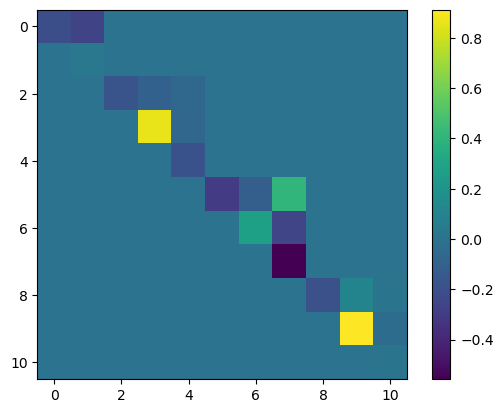

In [13]:
plt.imshow(hoppings[0 ,: , :])
plt.colorbar()

In [14]:
# make hopping matrices symmetric

for n in range(number_hopping_matrices):
    hoppings[n,:,:] = hoppings[n,:,:] + hoppings[n,:,:].T - np.diag(np.diag(hoppings[n,:,:]))

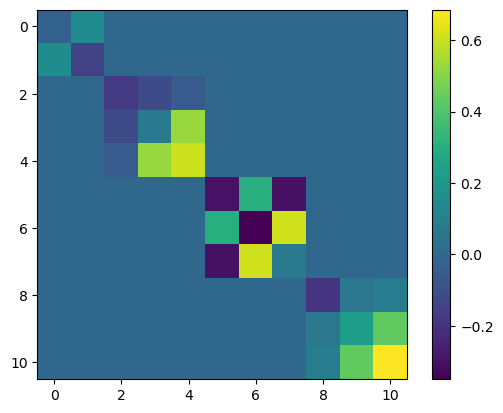

In [15]:
plt.imshow(hoppings[1 ,: , :])
plt.colorbar()

In [16]:
def check_hermitian(a, rtol=1e-05, atol=1e-08):
    return np.allclose(a, np.conjugate(a.T), rtol=rtol, atol=atol)

In [17]:
# check symmetry
for n in range(number_hopping_matrices):
    print(check_hermitian(hoppings[n, :, :]))

True
True
True
True
True
True


In [18]:
def hamiltonian(i, j, k):
    # indeces i, j and k is 2d array
    index_tuple = (i, j)

    result = complex(0, 0)

    # diagonals
    if i == j:
        result = on_site_energy[i] + 2 * hoppings[0, i, i] * np.cos(np.inner(k, delta_1)) + 2 * hoppings[1, i, i] * (np.cos(np.inner(k, delta_2)) + np.cos(np.inner(k, delta_3)))

    # off diagonals
    elif index_tuple == (2, 4) or index_tuple == (5, 7) or index_tuple == (8, 10):
        result = 2 * hoppings[0, i, j] * np.cos(np.inner(k, delta_1)) + hoppings[1, i, j] * (np.exp(-1j * np.inner(k, delta_2)) + np.exp(-1j * np.inner(k, delta_3))) + hoppings[2, i, j] * (np.exp(1j * np.inner(k, delta_2)) + np.exp(1j * np.inner(k, delta_3)))

    elif index_tuple == (0, 1) or index_tuple == (2, 3) or index_tuple == (3, 4) or index_tuple == (5, 6) or index_tuple == (6, 7) or index_tuple == (8, 9) or index_tuple == (9, 10):
        result = -2j * hoppings[0, i, j] * np.sin(np.inner(k, delta_1)) + hoppings[1, i, j] * (np.exp(-1j * np.inner(k, delta_2)) - np.exp(-1j * np.inner(k, delta_3))) + hoppings[2, i, j] * (-np.exp(1j * np.inner(k, delta_2)) + np.exp(1j * np.inner(k, delta_3)))

    elif index_tuple == (2, 0) or index_tuple == (4, 0) or index_tuple == (3, 1) or index_tuple == (9, 5) or index_tuple == (8, 6) or index_tuple == (10, 6) or index_tuple == (9, 7):
        result = hoppings[3, i, j] * (np.exp(1j * np.inner(k, delta_4)) - np.exp(1j * np.inner(k, delta_6)))

    elif index_tuple == (3, 0) or index_tuple == (2, 1) or index_tuple == (4, 1) or index_tuple == (8, 5) or index_tuple == (10, 5) or index_tuple == (9, 6) or index_tuple == (8, 7) or index_tuple == (10, 7):
        result = hoppings[3, i, j] * (np.exp(1j * np.inner(k, delta_4)) + np.exp(1j * np.inner(k, delta_6))) + hoppings[4, i, j] * np.exp(1j * np.inner(k, delta_5))
    
    else:
        result = complex(0, 0)
        
    return result

In [19]:
# non zero elements of hamiltonian

# diagonal
number_non_zero_elements = number_orbitals + 3 + 7 + 7 + 8

print(number_non_zero_elements)

36


In [20]:
def hamiltonian_matrix(k):
    # k is 2d array
    H = np.zeros((number_orbitals, number_orbitals), dtype=complex)

    for i in range(number_orbitals):
        for j in range(number_orbitals):
            H[i, j] = hamiltonian(i, j, k)
    # symmetrize
    H = H + np.conjugate(H.T) - np.diag(np.diag(H))
    return H

In [21]:
test_k = 0.1 * g_1 + 0.2 * g_2
test_hamiltonian = hamiltonian_matrix(test_k)

In [22]:
test_matrix = np.zeros((number_orbitals, number_orbitals))

print('upper triangle')
for i in range(number_orbitals):
    for j in range(i + 1, number_orbitals):
        
        if test_hamiltonian[i, j] != 0 and test_hamiltonian[j, i] == 0:
            print(f'row {i}, column {j}: hermitian possible')
        elif test_hamiltonian[i, j] != 0 and test_hamiltonian[j, i] != 0:
            print(f'row {i}, column {j}: hermitian NOT possible')
print('lower triangle')
for i in range(number_orbitals):
    for j in range(i):
        
        if test_hamiltonian[i, j] != 0 and test_hamiltonian[j, i] == 0:
            print(f'row {i}, column {j}: hermitian possible')
        elif test_hamiltonian[i, j] != 0 and test_hamiltonian[j, i] != 0:
            print(f'row {i}, column {j}: hermitian NOT possible')  

#print(test_matrix)
print(np.count_nonzero(test_hamiltonian))

upper triangle
row 0, column 1: hermitian NOT possible
row 0, column 2: hermitian NOT possible
row 0, column 3: hermitian NOT possible
row 0, column 4: hermitian NOT possible
row 1, column 2: hermitian NOT possible
row 1, column 3: hermitian NOT possible
row 1, column 4: hermitian NOT possible
row 2, column 3: hermitian NOT possible
row 2, column 4: hermitian NOT possible
row 3, column 4: hermitian NOT possible
row 5, column 6: hermitian NOT possible
row 5, column 7: hermitian NOT possible
row 5, column 8: hermitian NOT possible
row 5, column 9: hermitian NOT possible
row 5, column 10: hermitian NOT possible
row 6, column 7: hermitian NOT possible
row 6, column 8: hermitian NOT possible
row 6, column 9: hermitian NOT possible
row 6, column 10: hermitian NOT possible
row 7, column 8: hermitian NOT possible
row 7, column 9: hermitian NOT possible
row 7, column 10: hermitian NOT possible
row 8, column 9: hermitian NOT possible
row 8, column 10: hermitian NOT possible
row 9, column 10: her

In [23]:
#test_hamiltonian = test_hamiltonian + np.conjugate(test_hamiltonian.T) - np.diag(np.diag(test_hamiltonian))
check_hermitian(test_hamiltonian)

True

Text(0.5, 0.98, '$k_x=0.19758444362199956$ and $k_y=0.5703771585642194$')

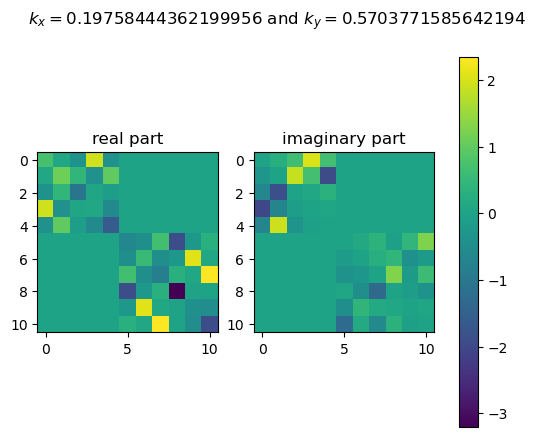

In [24]:
fig, axs = plt.subplots(ncols=2, nrows=1)

vmin = min(np.real(test_hamiltonian).min(), np.imag(test_hamiltonian).min())
vmax = max(np.real(test_hamiltonian).max(), np.imag(test_hamiltonian).max())

im1 = axs[0].imshow(np.real(test_hamiltonian), cmap="viridis", vmin=vmin, vmax=vmax)
axs[0].set_title('real part')

im2 = axs[1].imshow(np.imag(test_hamiltonian), cmap="viridis", vmin=vmin, vmax=vmax)
axs[1].set_title('imaginary part')

fig.colorbar(im1, ax=axs)
fig.suptitle(f'$k_x={test_k[0]}$ and $k_y={test_k[1]}$')

Text(0.5, 0.98, '$k_x=0.19758444362199956$ and $k_y=0.5703771585642194$')

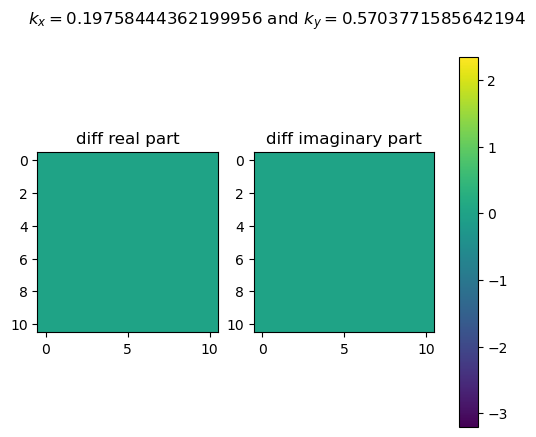

In [25]:
fig, axs = plt.subplots(ncols=2, nrows=1)

vmin = min(np.real(test_hamiltonian).min(), np.imag(test_hamiltonian).min())
vmax = max(np.real(test_hamiltonian).max(), np.imag(test_hamiltonian).max())

im1 = axs[0].imshow(np.real(test_hamiltonian - np.conjugate(test_hamiltonian).T), cmap="viridis", vmin=vmin, vmax=vmax)
axs[0].set_title('diff real part')

im2 = axs[1].imshow(np.imag(test_hamiltonian - np.conjugate(test_hamiltonian).T), cmap="viridis", vmin=vmin, vmax=vmax)
axs[1].set_title('diff imaginary part')

fig.colorbar(im1, ax=axs)
fig.suptitle(f'$k_x={test_k[0]}$ and $k_y={test_k[1]}$')

In [26]:
def next_nearest_neighbour_hamitonian_matrix(k):
    H_prime = np.zeros((number_orbitals, number_orbitals), dtype=complex)

    H_prime[8, 5] = hoppings[5, 8, 5] * (np.exp(1j * np.inner(k, delta_7)) + np.exp(1j * np.inner(k, delta_8)) + np.exp(1j * np.inner(k, delta_9)))
    H_prime[10, 5] = hoppings[5, 10, 5] * (np.exp(1j * np.inner(k, delta_7)) - 1/2 * np.exp(1j * np.inner(k, delta_8)) - 1/2 * np.exp(1j * np.inner(k, delta_9)))
    H_prime[9, 5] = np.sqrt(3)/2 * hoppings[5, 10, 5] * (-np.exp(1j * np.inner(k, delta_8)) + np.exp(1j * np.inner(k, delta_9)))
    H_prime[8, 7] = hoppings[5, 8, 7] * (np.exp(1j * np.inner(k, delta_7)) - 1/2 * np.exp(1j * np.inner(k, delta_8)) - 1/2 * np.exp(1j * np.inner(k, delta_9)))
    H_prime[8, 6] = np.sqrt(3)/2 * hoppings[5, 8, 7] * (-np.exp(1j * np.inner(k, delta_8)) + np.exp(1j * np.inner(k, delta_9)))
    H_prime[9, 6] = 3/4 * hoppings[5, 10, 7] * (np.exp(1j * np.inner(k, delta_8)) + np.exp(1j * np.inner(k, delta_9)))
    H_prime[9, 7] = np.sqrt(3)/4 * hoppings[5, 10, 7] * (np.exp(1j * np.inner(k, delta_8)) - np.exp(1j * np.inner(k, delta_9)))
    H_prime[10, 6] = H_prime[9, 7]
    H_prime[10, 7] = hoppings[5, 10, 7] * (np.exp(1j * np.inner(k, delta_7)) + 1/4 * np.exp(1j * np.inner(k, delta_8)) + 1/4 * np.exp(1j * np.inner(k, delta_9)))

    # symmetrize
    H_prime = H_prime + np.conjugate(H_prime.T) - np.diag(np.diag(H_prime)) 
    return H_prime

In [27]:
gamma = np.array([0.0, 0.0])

H_gamma = hamiltonian_matrix(gamma) + next_nearest_neighbour_hamitonian_matrix(gamma)

Text(0.5, 0.98, '$k_x=0.19758444362199956$ and $k_y=0.5703771585642194$')

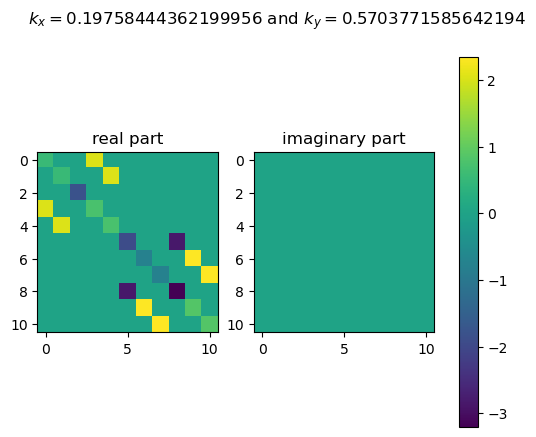

In [28]:
fig, axs = plt.subplots(ncols=2, nrows=1)

vmin = min(np.real(test_hamiltonian).min(), np.imag(test_hamiltonian).min())
vmax = max(np.real(test_hamiltonian).max(), np.imag(test_hamiltonian).max())

im1 = axs[0].imshow(np.real(H_gamma), cmap="viridis", vmin=vmin, vmax=vmax)
axs[0].set_title('real part')

im2 = axs[1].imshow(np.imag(H_gamma), cmap="viridis", vmin=vmin, vmax=vmax)
axs[1].set_title('imaginary part')

fig.colorbar(im1, ax=axs)
fig.suptitle(f'$k_x={test_k[0]}$ and $k_y={test_k[1]}$')

In [29]:
energies_gamma = np.linalg.eigvalsh(H_gamma)

In [30]:
print(energies_gamma)

[-6.03172038 -2.80091996 -2.80091996 -1.8189     -1.41329516 -1.41329516
  0.06182038  2.70179516  2.70179516  2.88591996  2.88591996]


In [31]:
K = 1/3 * (2 * g_1 - g_2)
K_2 = 1/3 * (g_1 + g_2)
M = 1/2 * g_1

print('g_1: ', g_1)
print('g_2: ', g_2)
print('K: ', K)

g_1:  [1.97584444 1.14075432]
g_2:  [0.         2.28150863]
K:  [1.31722962 0.        ]


In [32]:
# sample k-path
dk = 0.01

# Gamma to M
M_norm = np.linalg.norm(M)
n_M = int(M_norm/dk)
path_M = np.linalg.outer(np.linspace(0, 1, n_M, endpoint=False), M)

print('n_M: ',n_M)

# M to K
diff_vec = K - M
M_to_K_norm = np.linalg.norm(diff_vec)
n_M_to_K = int(M_to_K_norm/dk)
rs = np.linspace(0, 1, n_M_to_K, endpoint=False)
path_M_to_K = []
for r in rs:
    path_M_to_K.append(M + r * diff_vec)

path_M_to_K = np.array(path_M_to_K)

print('n_M_to_K: ',n_M_to_K)

# K to Gamma
K_norm = np.linalg.norm(K)
n_K = int(K_norm/dk)
rs = np.linspace(0, 1, n_K, endpoint=False)
path_K = []
for r in rs:
    path_K.append(K - r * K)

path_K = np.array(path_K)

print('n_K: ',n_K)

number_k_points = n_M + n_M_to_K + n_K
k_path = np.concatenate((path_M, path_M_to_K, path_K), axis=0)
print('n_k: ', number_k_points)
print(k_path.shape)

n_M:  114
n_M_to_K:  65
n_K:  131
n_k:  310
(310, 2)


In [33]:
print(path_M_to_K.shape)

(65, 2)


Text(0.5, 1.0, '2d hexagonal brillouin zone k-path')

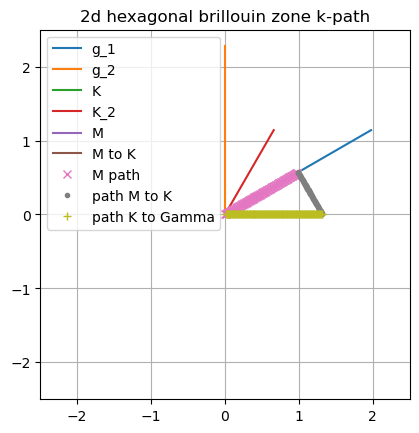

In [34]:
plt.plot([0, g_1[0]], [0, g_1[1]], '-', label='g_1')
plt.plot([0, g_2[0]], [0, g_2[1]], '-', label='g_2')
plt.plot([0, K[0]], [0, K[1]], '-', label='K')
plt.plot([0, K_2[0]], [0, K_2[1]], '-', label='K_2')
plt.plot([0, M[0]], [0, M[1]], '-', label='M')
plt.plot([M[0], K[0]], [M[1], K[1]], '-', label='M to K')
plt.plot(path_M[:, 0], path_M[:, 1], 'x', label='M path')
plt.plot(path_M_to_K[:, 0], path_M_to_K[:, 1], '.', label='path M to K')
plt.plot(path_K[:, 0], path_K[:, 1], '+', label='path K to Gamma')
plt.xlim((-2.5, 2.5))
plt.ylim((-2.5, 2.5))
plt.grid()
plt.legend()
ax = plt.gca()
ax.set_aspect('equal', adjustable='box')
plt.title('2d hexagonal brillouin zone k-path')

In [35]:
print(M)
print(np.pi/a_lattice)
print(np.pi/(np.sqrt(3) * a_lattice))

[0.98792222 0.57037716]
0.9879222181099978
0.5703771585642194


In [36]:
# solve along k-path
eigenvalues = []

for i in range(number_k_points):
    #print(k_path[i, :])
    h = hamiltonian_matrix(k_path[i, :]) + next_nearest_neighbour_hamitonian_matrix(k_path[i, :])
    e = np.linalg.eigvalsh(h)
    eigenvalues.append(e)

eigenvalues = np.array(eigenvalues)
print(eigenvalues.shape)

(310, 11)


In [48]:
special_points = np.array([0.0, n_M, n_M + n_M_to_K, number_k_points])
print(special_points)

[  0. 114. 179. 310.]


In [49]:
results_folder = Path.cwd() / 'DOS_calculations'
results_folder.mkdir(exist_ok=True)

np.save(results_folder / 'bandstructure_tmdc', eigenvalues)
np.save(results_folder / 'bandstructure_tmdc_special_points', special_points)

In [44]:
band_0 = eigenvalues[:, 0]
print(band_0.shape)
print(n_M)
print(n_M + n_M_to_K)

(310,)
114
179


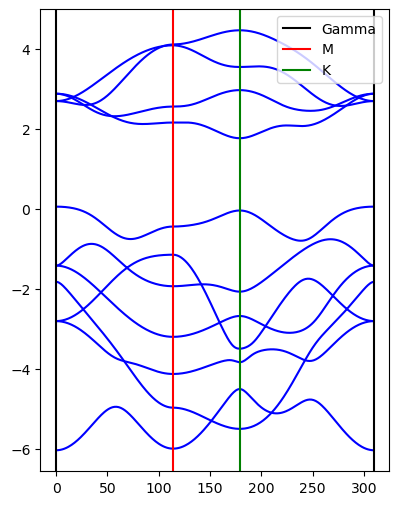

In [39]:
bands_to_plot = 11
plt.figure(figsize=(4.5, 6))

for i in range(bands_to_plot):
    plt.plot(eigenvalues[:, i], color='blue')

plt.axvline(0, color='black',label='Gamma')
plt.axvline(number_k_points, color='black')
plt.axvline(n_M, color='red',label='M')
plt.axvline(n_M + n_M_to_K, color='green',label='K')
plt.legend()

plt.show()

In [40]:
print(eigenvalues[n_M + n_M_to_K, :])

[-5.49588957 -4.50081174 -3.82867316 -3.49121797 -2.67337875 -2.06437667
 -0.03470808  1.77280987  2.97590107  3.55461406  4.47253092]


In [41]:
test_array = np.zeros((3, 2, 2))

charge = np.array([[1.0, 2.0], [3.0, 4.0]])

print(charge)

[[1. 2.]
 [3. 4.]]


In [42]:
test_array[0, :,:] = charge

print(test_array[0, :, :])

[[1. 2.]
 [3. 4.]]


In [43]:
np.save('test.txt', test_array)